Memulai analisis & perbandingan model...

           HASIL PERBANDINGAN MODEL
Model                             Akurasi
------------------------------------------------------------
Random Forest                     100.00%
Decision Tree                     100.00%


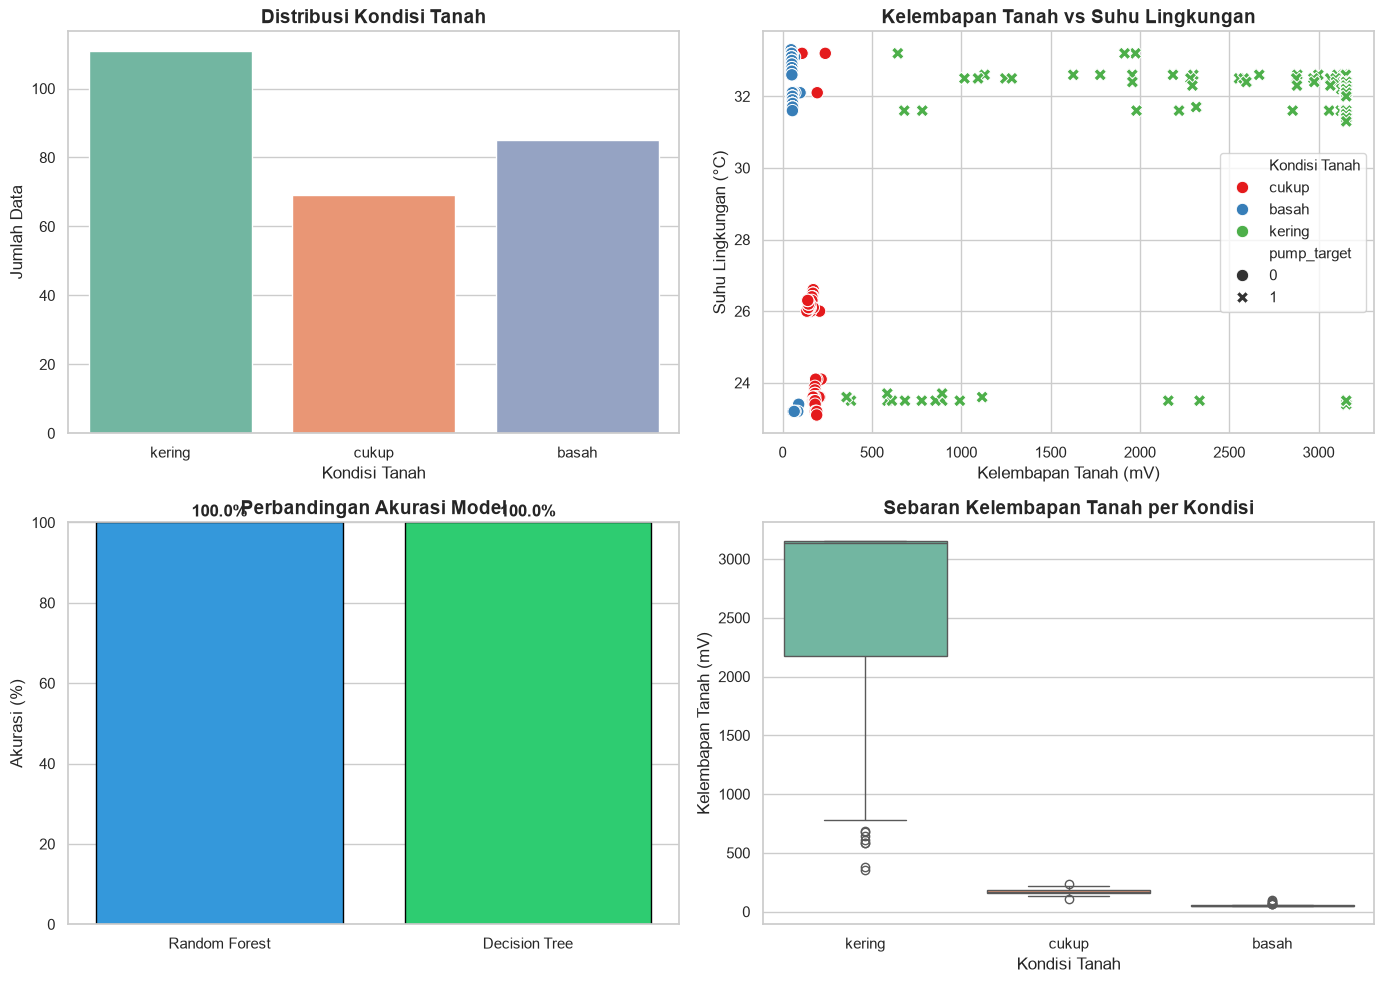

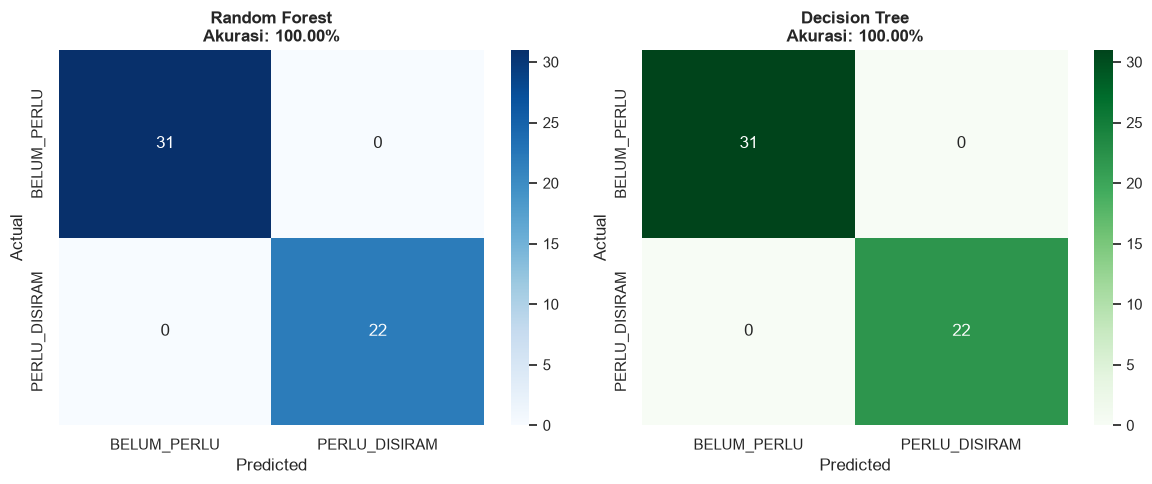


Selesai! Sekarang ada grafik yang lebih lengkap.


In [2]:
# ============================================================
# KODE GABUNGAN + GRAFIK LEBIH LENGKAP
# Random Forest vs Decision Tree
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)

print("Memulai analisis & perbandingan model...\n")

# ============================================================
# 1. LOAD & PREPROCESSING
# ============================================================
df = pd.read_csv("dataset_kebun_pintar.csv")
df = df.drop_duplicates()

df["Kondisi Tanah"] = df["Kondisi Tanah"].str.lower().str.strip()

df["pump_target"] = df["pump_target"].map({
    "PERLU_DISIRAM": 1,
    "BELUM_PERLU_DISIRAM": 0
})
df = df.dropna(subset=["pump_target"])
df["pump_target"] = df["pump_target"].astype(int)

df = df.drop(columns=["timestamp_WIB", "Suhu Air", "Prediksi suhu air", "Status pompa"], errors="ignore")

le_kondisi = LabelEncoder()
df["Kondisi_enc"] = le_kondisi.fit_transform(df["Kondisi Tanah"])

features = ["Kelembapan Tanah", "Suhu lingkungan", "Kondisi_enc"]
X = df[features]
y = df["pump_target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# 2. TRAINING MODEL
# ============================================================
rf = RandomForestClassifier(n_estimators=100, max_depth=6, class_weight="balanced", random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
akurasi_rf = accuracy_score(y_test, y_pred_rf) * 100

dt = DecisionTreeClassifier(max_depth=5, min_samples_split=5, min_samples_leaf=3,
                            class_weight="balanced", random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)
akurasi_dt = accuracy_score(y_test, y_pred_dt) * 100

# ============================================================
# 3. TABEL PERBANDINGAN AKURASI
# ============================================================
print("=" * 60)
print("           HASIL PERBANDINGAN MODEL")
print("=" * 60)
print(f"{'Model':<25} {'Akurasi':>15}")
print("-" * 60)
print(f"{'Random Forest':<25} {akurasi_rf:>14.2f}%")
print(f"{'Decision Tree':<25} {akurasi_dt:>14.2f}%")
print("=" * 60)

# ============================================================
# 4. GRAFIK 1: Distribusi Kondisi Tanah
# ============================================================
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
sns.countplot(data=df, x="Kondisi Tanah", palette="Set2", order=["kering", "cukup", "basah"])
plt.title("Distribusi Kondisi Tanah", fontsize=14, fontweight="bold")
plt.xlabel("Kondisi Tanah")
plt.ylabel("Jumlah Data")

# ============================================================
# 5. GRAFIK 2: Kelembapan Tanah vs Suhu Lingkungan
# ============================================================
plt.subplot(2, 2, 2)
sns.scatterplot(
    data=df, 
    x="Kelembapan Tanah", 
    y="Suhu lingkungan", 
    hue="Kondisi Tanah",
    style="pump_target",
    palette="Set1",
    s=80
)
plt.title("Kelembapan Tanah vs Suhu Lingkungan", fontsize=14, fontweight="bold")
plt.xlabel("Kelembapan Tanah (mV)")
plt.ylabel("Suhu Lingkungan (°C)")

# ============================================================
# 6. GRAFIK 3: Perbandingan Akurasi
# ============================================================
plt.subplot(2, 2, 3)
models = ["Random Forest", "Decision Tree"]
scores = [akurasi_rf, akurasi_dt]
colors = ["#3498db", "#2ecc71"]

bars = plt.bar(models, scores, color=colors, edgecolor="black")
plt.ylim(0, 100)
plt.title("Perbandingan Akurasi Model", fontsize=14, fontweight="bold")
plt.ylabel("Akurasi (%)")

for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, 
             f"{score:.1f}%", ha="center", fontweight="bold")

# ============================================================
# 7. GRAFIK 4: Boxplot Kelembapan berdasarkan Kondisi
# ============================================================
plt.subplot(2, 2, 4)
sns.boxplot(data=df, x="Kondisi Tanah", y="Kelembapan Tanah", palette="Set2",
            order=["kering", "cukup", "basah"])
plt.title("Sebaran Kelembapan Tanah per Kondisi", fontsize=14, fontweight="bold")
plt.xlabel("Kondisi Tanah")
plt.ylabel("Kelembapan Tanah (mV)")

plt.tight_layout()
plt.show()

# ============================================================
# 8. CONFUSION MATRIX BERDAMPINGAN
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["BELUM_PERLU", "PERLU_DISIRAM"],
            yticklabels=["BELUM_PERLU", "PERLU_DISIRAM"])
axes[0].set_title(f"Random Forest\nAkurasi: {akurasi_rf:.2f}%", fontweight="bold")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["BELUM_PERLU", "PERLU_DISIRAM"],
            yticklabels=["BELUM_PERLU", "PERLU_DISIRAM"])
axes[1].set_title(f"Decision Tree\nAkurasi: {akurasi_dt:.2f}%", fontweight="bold")
axes[1].set_ylabel("Actual")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.show()

print("\nSelesai! Sekarang ada grafik yang lebih lengkap.")